# Implementation of a simple EKF

-> The system in question:

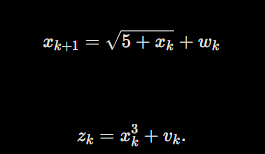

Both in. and output equation are non linear, hence they have to kbe linearised. The resulting Jacobians are:

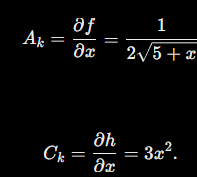
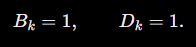

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Initialize simulation variables
# ------------------------------------------------------------

SigmaW = 1.0       # Process noise covariance
SigmaV = 2.0       # Sensor noise covariance
maxIter = 40


# ------------------------------------------------------------
# Random-number generator
# ------------------------------------------------------------

# Fixed seed -> reproducible results
rng = np.random.default_rng(1)


# ------------------------------------------------------------
# Initialize true state and EKF
# ------------------------------------------------------------

xtrue = 2.0 + rng.normal()

xhat = 2.0
SigmaX = 1.0

u = 0.0


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

xstore = np.zeros(maxIter + 1)
xhatstore = np.zeros(maxIter)
SigmaXstore = np.zeros(maxIter)

xstore[0] = xtrue


# ------------------------------------------------------------
# EKF loop
# ------------------------------------------------------------

for k in range(maxIter):

    # ========================================================
    # EKF Step 0:
    # Linearize state equation
    # ========================================================

    Ahat = 0.5 / np.sqrt(5.0 + xhat)
    Bhat = 1.0


    # ========================================================
    # EKF Step 1:
    # State estimate time update
    # ========================================================

    xhat = np.sqrt(5.0 + xhat)


    # ========================================================
    # EKF Step 2:
    # Error covariance time update
    # ========================================================

    SigmaX = (
        Ahat**2 * SigmaX
        + Bhat**2 * SigmaW
    )


    # ========================================================
    # Simulate real system
    # ========================================================

    w = np.sqrt(SigmaW) * rng.normal()
    v = np.sqrt(SigmaV) * rng.normal()

    ztrue = xtrue**3 + v

    xtrue = np.sqrt(5.0 + xtrue) + w


    # ========================================================
    # EKF Step 3:
    # Estimate system output
    # ========================================================

    Chat = 3.0 * xhat**2
    Dhat = 1.0

    zhat = xhat**3


    # ========================================================
    # EKF Step 4:
    # Kalman gain
    # ========================================================

    L = (
        SigmaX * Chat
        /
        (
            Chat**2 * SigmaX
            + Dhat**2 * SigmaV
        )
    )


    # ========================================================
    # EKF Step 5:
    # Measurement update
    # ========================================================

    innovation = ztrue - zhat

    xhat = xhat + L * innovation

    # Prevent sqrt(5 + xhat) from becoming invalid
    xhat = max(-5.0, xhat)


    # ========================================================
    # EKF Step 6:
    # Error covariance measurement update
    # ========================================================

    SigmaX = SigmaX - L * Chat * SigmaX


    # ========================================================
    # Store results
    # ========================================================

    xstore[k + 1] = xtrue
    xhatstore[k] = xhat
    SigmaXstore[k] = SigmaX

Now for the plots

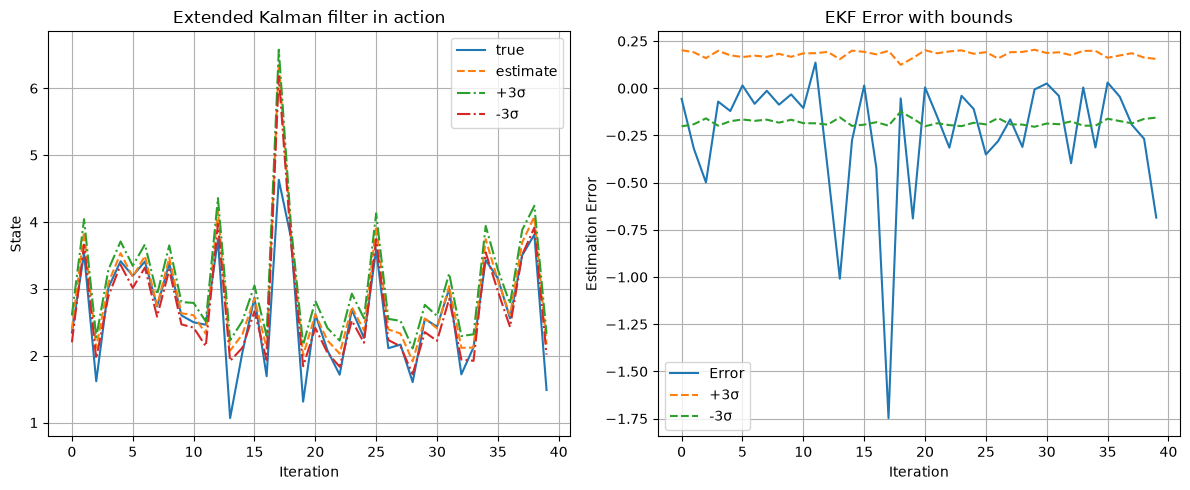

In [2]:
iterations = np.arange(maxIter)

bounds = 3.0 * np.sqrt(SigmaXstore)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# ------------------------------------------------------------
# State estimate
# ------------------------------------------------------------

ax[0].plot(
    iterations,
    xstore[:maxIter],
    label="true"
)

ax[0].plot(
    iterations,
    xhatstore,
    "--",
    label="estimate"
)

ax[0].plot(
    iterations,
    xhatstore + bounds,
    "-.",
    label="+3σ"
)

ax[0].plot(
    iterations,
    xhatstore - bounds,
    "-.",
    label="-3σ"
)

ax[0].grid()
ax[0].legend()
ax[0].set_title("Extended Kalman filter in action")
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("State")


# ------------------------------------------------------------
# Estimation error
# ------------------------------------------------------------

estErr = xstore[:maxIter] - xhatstore

ax[1].plot(
    iterations,
    estErr,
    label="Error"
)

ax[1].plot(
    iterations,
    bounds,
    "--",
    label="+3σ"
)

ax[1].plot(
    iterations,
    -bounds,
    "--",
    label="-3σ"
)

ax[1].grid()
ax[1].legend()
ax[1].set_title("EKF Error with bounds")
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Estimation Error")

plt.tight_layout()
plt.show()